# 07 · EDA: Human Activity Recognition — Accelerometer Signals
**Group 10: Sequential Human Activity Recognition**
Algorithms: Markov models, HMM, forward-backward, Viterbi · Objective: infer activity-state sequences from accelerometer time series

Dataset: UCI HAR (smartphone accelerometer + gyroscope, 30 subjects, 6 activities),
https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones
Saved locally at `data/raw/har/UCI HAR Dataset/`.

In [1]:
# --- Colab-friendly setup: installs, paths, dataset download, plot helpers (no repo dependency) ---
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hmmlearn"], check=False)

import os, json, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

RAW, PROCESSED, FIGURES, MODELS = Path("data/raw"), Path("data/processed"), Path("outputs/figures"), Path("outputs/models")
for d in (RAW, PROCESSED, FIGURES, MODELS):
    d.mkdir(parents=True, exist_ok=True)

HAR = RAW / "har" / "UCI HAR Dataset"
if not HAR.exists():
    url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
    zpath = RAW / "har.zip"
    urllib.request.urlretrieve(url, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(RAW / "har")
    with zipfile.ZipFile(RAW / "har" / "UCI HAR Dataset.zip") as z:
        z.extractall(RAW / "har")
    print("Downloaded and extracted UCI HAR Dataset")

BLUE, ORANGE = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#ffffff"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div_blue_red", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f2a3a2", "#e34948", "#9e2323"])

def set_style():
    mpl.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "semibold",
        "axes.titlelocation": "left", "axes.titlepad": 12, "axes.labelsize": 11, "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
        "text.color": INK, "legend.frameon": False, "legend.fontsize": 10, "lines.linewidth": 2,
        "axes.prop_cycle": mpl.cycler(color=SERIES),
    })

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()

def save_json(obj, name):
    (MODELS / f"{name}.json").write_text(json.dumps(obj, indent=2, default=float))

set_style()
ACT = pd.read_csv(HAR / "activity_labels.txt", sep=r"\s+", header=None, names=["id", "activity"])
ACT_MAP = dict(zip(ACT.id, ACT.activity))
print(ACT_MAP)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /Users/ompathania/Desktop/ML_Project_5th_sem/code/.venv/bin/python -m pip install --upgrade pip


Downloaded and extracted UCI HAR Dataset
{1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


## 1. Load raw triaxial total acceleration (body + gravity), labels and subjects
Each row is one 2.56 s window (128 samples at 50 Hz, 50% overlap). We combine train+test so we have the full
continuous recordings per subject.

In [2]:
def load_signal(split, axis):
    f = HAR / split / "Inertial Signals" / f"total_acc_{axis}_{split}.txt"
    return pd.read_csv(f, sep=r"\s+", header=None).values

def load_split(split):
    sig = np.stack([load_signal(split, a) for a in "xyz"], axis=-1)       # (windows, 128, 3)
    y = pd.read_csv(HAR / split / f"y_{split}.txt", header=None)[0].values
    subj = pd.read_csv(HAR / split / f"subject_{split}.txt", header=None)[0].values
    return sig, y, subj

sig_tr, y_tr, subj_tr = load_split("train")
sig_te, y_te, subj_te = load_split("test")
sig = np.concatenate([sig_tr, sig_te]); y = np.concatenate([y_tr, y_te]); subj = np.concatenate([subj_tr, subj_te])
print(f"Windows: {sig.shape[0]}, samples/window: {sig.shape[1]}, axes: {sig.shape[2]}, subjects: {len(set(subj))}")
print("Missing:", np.isnan(sig).sum(), "| Activities:", pd.Series(y).map(ACT_MAP).value_counts().to_dict())

Windows: 10299, samples/window: 128, axes: 3, subjects: 30
Missing: 0 | Activities: {'LAYING': 1944, 'STANDING': 1906, 'SITTING': 1777, 'WALKING': 1722, 'WALKING_UPSTAIRS': 1544, 'WALKING_DOWNSTAIRS': 1406}


## 2. Feature engineering: per-window summary features (HMM observations)
Raw 128x3 signals are too high-dimensional for a small HMM, so each window is summarised by features that are
well known to separate activities: mean, std, min/max, signal magnitude energy, and a crude "jerk" (sample-to-sample
difference) measure for dynamic vs static activities.

In [3]:
def window_features(w):
    mag = np.linalg.norm(w, axis=1)
    jerk = np.diff(w, axis=0)
    return {
        "mean_mag": mag.mean(), "std_mag": mag.std(), "energy": (w ** 2).mean(),
        "mean_x": w[:, 0].mean(), "mean_y": w[:, 1].mean(), "mean_z": w[:, 2].mean(),
        "std_x": w[:, 0].std(), "std_y": w[:, 1].std(), "std_z": w[:, 2].std(),
        "jerk_energy": (jerk ** 2).mean(),
    }

feat = pd.DataFrame([window_features(sig[i]) for i in range(sig.shape[0])])
feat["activity_id"] = y
feat["activity"] = pd.Series(y).map(ACT_MAP).values
feat["subject"] = subj
feat.to_csv(PROCESSED / "har_features.csv", index=False)
feat.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean_mag,10299.0,1.032,0.020,0.971,1.020,1.032,1.045,1.099
std_mag,10299.0,0.133,0.152,0.001,0.003,0.012,0.260,0.649
energy,10299.0,0.369,0.029,0.326,0.348,0.358,0.389,0.520
mean_x,10299.0,0.808,0.365,-0.371,0.906,0.986,1.012,1.055
mean_y,10299.0,0.022,0.379,-0.981,-0.225,-0.125,0.142,1.005
mean_z,10299.0,0.085,0.329,-0.988,-0.120,0.031,0.206,0.977
std_x,10299.0,0.127,0.142,0.001,0.004,0.015,0.243,0.649
std_y,10299.0,0.083,0.085,0.002,0.005,0.022,0.161,0.369
std_z,10299.0,0.069,0.072,0.003,0.006,0.021,0.129,0.357
jerk_energy,10299.0,0.004,0.006,0.000,0.000,0.000,0.008,0.059


## 3. EDA: how activities differ, and whether the sequence structure is real

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


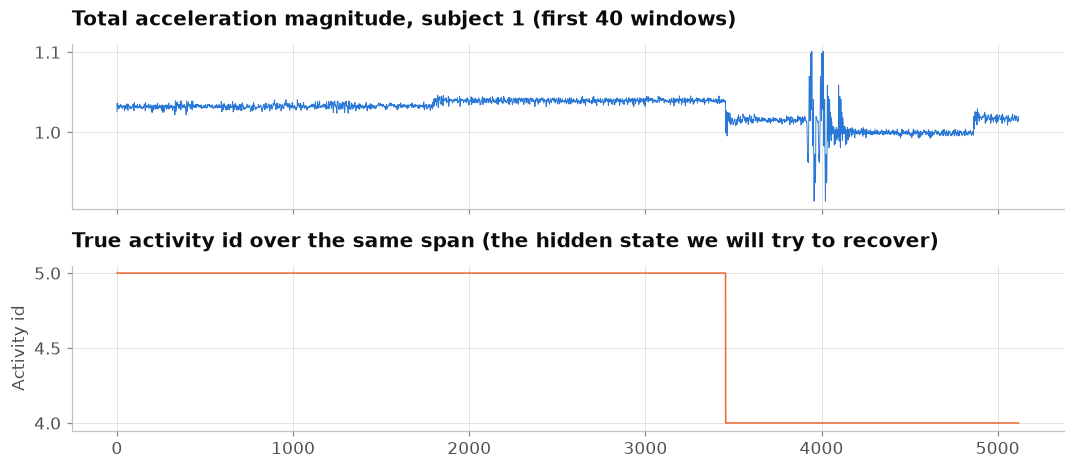

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.4), sharex=True)
s0 = subj_tr[0]
idx = np.where(subj_tr == s0)[0][:40]
flat = sig_tr[idx].reshape(-1, 3)
act_flat = np.repeat(y_tr[idx], sig_tr.shape[1])
axes[0].plot(np.linalg.norm(flat, axis=1), color=BLUE, lw=0.6)
axes[0].set(title=f"Total acceleration magnitude, subject {s0} (first 40 windows)")
axes[1].plot(act_flat, color=SERIES[1], lw=1)
axes[1].set(title="True activity id over the same span (the hidden state we will try to recover)", ylabel="Activity id")
save(fig, "har_signal_and_activity")

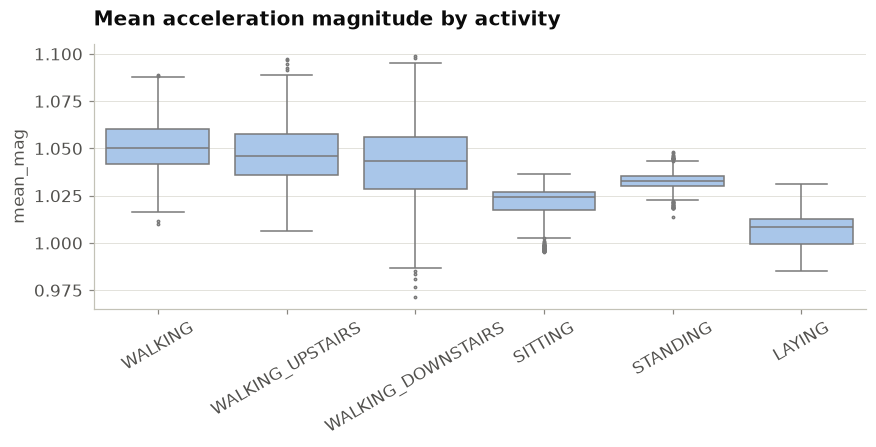

In [5]:
order = ACT.activity.tolist()
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=feat, x="activity", y="mean_mag", order=order, color="#9ec5f4", ax=ax, fliersize=1.5)
ax.set(title="Mean acceleration magnitude by activity", xlabel="")
ax.tick_params(axis="x", rotation=30)
save(fig, "har_feature_by_activity")

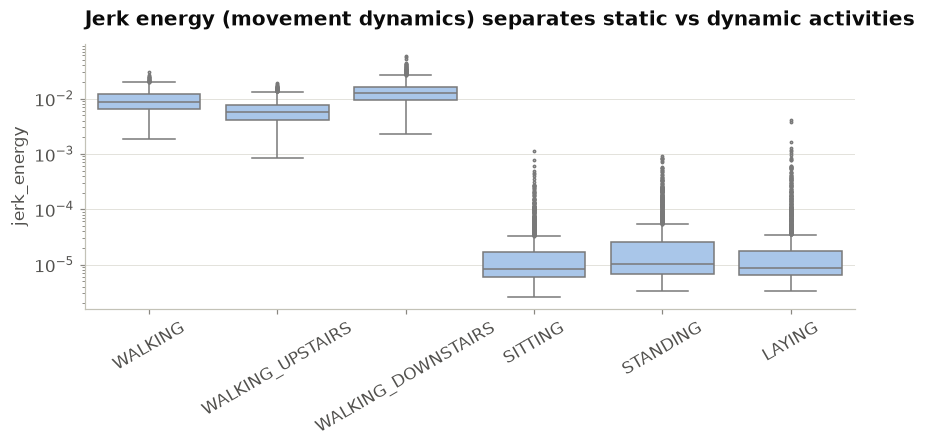

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=feat, x="activity", y="jerk_energy", order=order, color="#9ec5f4", ax=ax, fliersize=1.5)
ax.set(title="Jerk energy (movement dynamics) separates static vs dynamic activities", xlabel="", yscale="log")
ax.tick_params(axis="x", rotation=30)
save(fig, "har_jerk_by_activity")

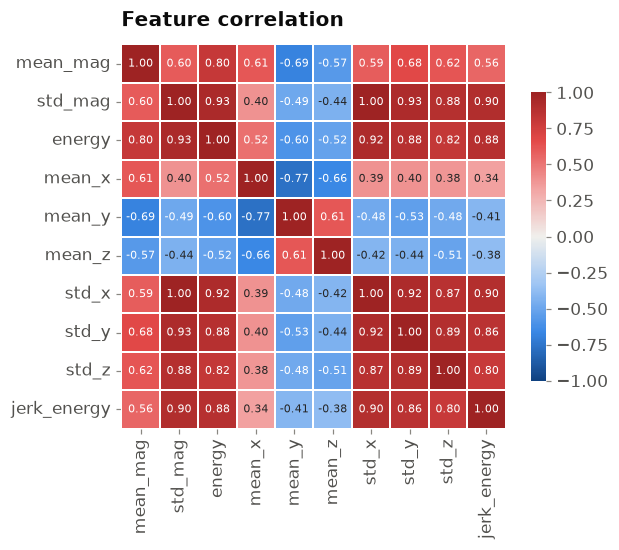

In [7]:
num_cols = [c for c in feat.columns if c not in ("activity_id", "activity", "subject")]
corr = feat[num_cols].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, linewidths=1,
            linecolor=SURFACE, cbar_kws={"shrink": 0.75}, annot_kws={"fontsize": 7.5}, ax=ax)
ax.set(title="Feature correlation"); ax.grid(False)
save(fig, "har_feature_correlation")

**Insights**
1. The six activities fall into two clear super-groups: **static** (Sitting, Standing, Laying — low magnitude, low jerk)
   and **dynamic** (Walking, Walking_Upstairs, Walking_Downstairs — high jerk energy), which is exactly the kind of
   structure a hidden-state model should recover.
2. **Activities persist across consecutive windows** (the true-activity plot is piecewise-constant), confirming the
   Markov assumption: the state at window t is highly predictive of the state at window t+1.
3. Engineered features are strongly correlated (mean/std of magnitude with per-axis std), so a handful of features
   capture most of the signal — useful for keeping the HMM's emission model simple (notebook 08).